# Netting Sets & CSA Collateral Modeling

A collateral agreement looks like a promise that exposure will be covered, but the details decide how much risk is really left. A threshold leaves an unsecured layer, a minimum transfer amount adds another, and the days it takes to close out a defaulted bank leave room for the market to move. This notebook measures what each bank's collateral terms actually remove, and what they cost the treasury in collateral it has to post.

**What it does.** It takes an MDB-style hedge book of SOFR swaps with five banks and measures how much counterparty exposure each bank's ISDA Credit Support Annex (CSA) removes. It covers thresholds, minimum transfer amounts, independent amounts and the margin period of risk, and also tracks the collateral the MDB itself has to post.

**Data.** Today's SOFR curve and three years of Treasury volatility (U.S. Treasury and FRED). The hedge book and the CSA terms are synthetic but realistic.

**Methods.** Hull–White Monte Carlo with exact swap revaluation on a grid that includes the margin-period lag dates, and the classical collateral model (collateral is called on the value one MPoR earlier).

On top of that sits an XGBoost surrogate trained on 2,500 simulated netting-set and CSA designs, explained with SHAP.

**Key output.** Collateralised and uncollateralised EE, PFE and EAD by bank, sensitivity to MPoR and threshold, the collateral the MDB may have to post (a liquidity need), and a CSA negotiation tool that ranks which terms buy the most exposure reduction.

## 1. Why collateral terms matter to a credit officer

Gross exposure is only the starting point. In practice almost every swap of a multilateral development bank sits under an ISDA Master Agreement with a **CSA**, and the CSA terms decide how much of that exposure is left:

| CSA term | What it does | Effect on exposure |
|---|---|---|
| **Threshold (TH)** | uncollateralised amount each side tolerates | exposure up to TH stays unsecured |
| **Minimum transfer amount (MTA)** | smallest call worth making | adds up to MTA of unsecured exposure |
| **Independent amount (IA)** | extra collateral posted up front | reduces exposure one for one |
| **Margin period of risk (MPoR)** | time from the last good margin call until the position is closed out after a default | the market can move for MPoR days with no new collateral |
| **One-way vs two-way** | whether the MDB also posts | two-way CSAs create a **liquidity need** and put posted collateral at risk |

Historically, AAA-rated MDBs often signed **one-way** CSAs: banks posted collateral and the MDB did not. Most have since moved to **two-way, zero-threshold** CSAs, which banks prefer under Basel III capital rules. This notebook quantifies the trade-off: less credit exposure, but collateral outflows the treasury has to fund.

**The classical collateral model** (Gregory; Basel IMM). Let $V_t$ be the netted value to us and $\delta$ the MPoR. Collateral held at $t$ reflects the last margin call, made at $t-\delta$:

$$
C_t = \underbrace{\big(V_{t-\delta}-TH_{cp}-MTA\big)^+}_{\text{held from the bank}} \;-\; \underbrace{\big(-V_{t-\delta}-TH_{own}-MTA\big)^+}_{\text{posted by us (two-way only)}},
\qquad E_t = \big(V_t - C_t - IA\big)^+ .
$$

Posted variation margin is not segregated, so when $C_t<0$ the collateral we gave the bank is part of our claim in its default. Adding MTA to the threshold is the usual conservative simplification of a daily margining process (it is also how the Basel shortcut method treats MTA).

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import shap
import xgboost as xgb
from scipy.optimize import least_squares
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

N_PATHS = 3_000  # Monte Carlo paths for the book
# paths per design in the 2,500-design training set (speed)
N_PATHS_ML = 1_500
N_DESIGNS = 2_500  # netting-set/CSA designs for the XGBoost surrogate
DT = 1 / 12  # monthly exposure grid
# Basel: 10 business days standard, 20 for large or disputed netting sets
MPOR_DAYS = [10, 20]
PFE_QUANTILE = 0.975
ALPHA_IMM = 1.4
SEED = 11

print(
    f"QuantLib {ql.__version__} · xgboost {xgb.__version__} · shap"
    f" {shap.__version__} · run on {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · xgboost 3.4.1 · shap 0.54.1 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

## 3. Market data, SOFR curve and Hull–White calibration

The Treasury par curve is bootstrapped with QuantLib, the swap-spread term structure turns it into a SOFR curve, and $(a,\sigma)$ are fitted to the realised volatility of Treasury yields over three years.

In [3]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [4]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [5]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

## 4. The MDB hedge book and its CSAs

An MDB treasury has two natural swap flows, and they point in opposite directions:

- **Issuance hedges.** The MDB issues fixed-rate bonds (3–10 years) and swaps them to SOFR, so it **receives fixed**.
- **Asset swaps.** It buys fixed-rate bonds for its liquidity portfolio and swaps them to floating, so it **pays fixed**.

Thirty swaps are spread across five banks, 60% of them seasoned with realistic mark-to-market. The CSA terms below are typical of the current MDB landscape, including one legacy one-way CSA and one uncollateralised relationship.

In [6]:
rng = np.random.default_rng(SEED)
COUNTERPARTIES = ["Bank A", "Bank B", "Bank C", "Bank D", "Bank E"]
INF = np.inf
CSA = pd.DataFrame(
    [
        # rating, CSA type, threshold the bank gets (USD mm), our threshold,
        # MTA, independent amount posted by the bank
        ("Bank A", "AA", "two-way", 10.0, 10.0, 0.50, 0.0),
        ("Bank B", "A", "two-way", 0.0, 0.0, 0.50, 0.0),
        ("Bank C", "A", "one-way (legacy)", 0.0, INF, 0.50, 0.0),
        ("Bank D", "BBB", "two-way + IA", 0.0, 0.0, 0.25, 5.0),
        ("Bank E", "A", "no CSA", INF, INF, 0.00, 0.0),
    ],
    columns=["counterparty", "rating", "csa", "th_cp", "th_own", "mta", "ia"],
).set_index("counterparty")

trades = []
for i in range(30):
    issuance = rng.random() < 0.55
    first_pay = rng.integers(1, 13) / 12
    n_pay = int(
        rng.choice([3, 5, 5, 7, 10])
        if issuance
        else rng.choice([2, 3, 5, 7, 10, 12, 15])
    )
    k_par = par_rate(CURVE, first_pay, n_pay)
    fixed = k_par + (rng.normal(0, 0.0075) if rng.random() < 0.6 else 0.0)
    trades.append({
        "trade_id": f"HDG-{i+1:03d}",
        "counterparty": COUNTERPARTIES[i % 5],
        "purpose": "issuance hedge" if issuance else "asset swap",
        "direction": "receive fixed" if issuance else "pay fixed",
        "notional_mm": float(rng.choice([50, 100, 150, 250, 300, 500])),
        "first_pay": first_pay,
        "n_pay": n_pay,
        "fixed_rate": fixed,
        "par_rate": k_par,
        "maturity_y": first_pay + n_pay - 1,
    })
book = pd.DataFrame(trades)
book["omega"] = np.where(book["direction"] == "receive fixed", 1.0, -1.0)

display(CSA.replace(INF, "∞"))
book.groupby(["counterparty", "purpose"]).agg(
    trades=("trade_id", "count"),
    notional_mm=("notional_mm", "sum"),
    max_maturity_y=("maturity_y", "max"),
).unstack(fill_value=0)

,rating,csa,th_cp,th_own,mta,ia
counterparty,,,,,,
Bank A,AA,two-way,10.00,10.00,0.50,0.00
Bank B,A,two-way,0.00,0.00,0.50,0.00
Bank C,A,one-way (legacy),0.00,∞,0.50,0.00
Bank D,BBB,two-way + IA,0.00,0.00,0.25,5.00
Bank E,A,no CSA,∞,∞,0.00,0.00


trades                notional_mm                 \
purpose      asset swap issuance hedge  asset swap issuance hedge   
counterparty                                                        
Bank A                2              4      150.00       1,100.00   
Bank B                2              4      550.00       1,550.00   
Bank C                2              4      400.00         800.00   
Bank D                3              3      200.00         450.00   
Bank E                4              2    1,350.00         350.00   

             max_maturity_y                 
purpose          asset swap issuance hedge  
counterparty                                
Bank A                 6.92           7.00  
Bank B                14.92           9.75  
Bank C                10.00           6.92  
Bank D                 6.83           9.67  
Bank E                14.25           4.67

## 5. Simulation grid with margin-period lags

Exposure is measured monthly. The collateral at each monthly date depends on the value **10 or 20 business days earlier**, so those lag dates are added to the simulation grid. The Hull–White factor is simulated exactly on the irregular grid, which means no interpolation error in $V_{t-\delta}$.

**Trade cash flows during the MPoR.** A swap payment that falls inside the margin period makes the value jump. If we assume the defaulting bank stops paying but we keep paying (the "Classical−" assumption), every payment date shows an artificial exposure spike the size of a coupon, and it does not depend on the MPoR at all.

We follow the common "Classical+" convention (Andersen, Pykhtin & Sokol, 2017): both sides keep paying trade flows during the MPoR. So the lag value $V_{t-\delta}$ includes only the cash flows still outstanding at $t$. A first version of this notebook without the adjustment produced residual PFEs dominated by coupon spikes and insensitive to MPoR, which is why the convention matters.

In [7]:
HORIZON = book["maturity_y"].max()
MONTHLY = np.round(np.arange(0, HORIZON + DT / 2, DT), 10)
LAGS = {d: np.round(np.maximum(MONTHLY - d / 252, 0.0), 10) for d in MPOR_DAYS}
GRID = np.unique(np.concatenate([MONTHLY, *LAGS.values()]))
I_NOW = np.searchsorted(GRID, MONTHLY)
I_LAG = {d: np.searchsorted(GRID, LAGS[d]) for d in MPOR_DAYS}
# Each lag date values only the cash flows still outstanding at its exposure
# date ("Classical+")
CUTOFF = GRID.copy()
for d in MPOR_DAYS:
    CUTOFF[I_LAG[d]] = np.maximum(CUTOFF[I_LAG[d]], MONTHLY)

hw = HullWhite(CURVE, A_HW, SIGMA_HW)
t0 = time.perf_counter()
sim = hw.simulate(GRID, N_PATHS, seed=SEED + 1)
# trades × paths × grid dates
values = revalue_book(book, hw, sim, cutoff=CUTOFF)
netted = {
    cp: values[(book["counterparty"] == cp).to_numpy()].sum(axis=0)
    for cp in COUNTERPARTIES
}
print(
    f"{len(book)} swaps × {N_PATHS:,} paths × {len(GRID)} grid dates"
    f" ({len(MONTHLY)} monthly + lag dates) revalued in"
    f" {time.perf_counter() - t0:.1f}s · book MtM today"
    f" {values[:, :, 0].mean(axis=1).sum():+.1f}mm"
)

30 swaps × 3,000 paths × 538 grid dates (180 monthly + lag dates) revalued in 2.0s · book MtM today -46.6mm


## 6. Applying the CSA

The function below implements the formula in section 1 for any set of terms. Infinite thresholds mean "no collateral in that direction".

In [8]:
def apply_csa(v_now, v_lag, th_cp, th_own, mta, ia):
    """
    Collateral and collateralised exposure value (both paths × dates, USD mm).
    """
    held = (
        np.maximum(v_lag - th_cp - mta, 0)
        if np.isfinite(th_cp)
        else np.zeros_like(v_lag)
    )
    posted = (
        np.maximum(-v_lag - th_own - mta, 0)
        if np.isfinite(th_own)
        else np.zeros_like(v_lag)
    )
    collateral = held - posted
    return v_now - collateral - ia, collateral


def netting_set_report(cp, mpor=10, terms=None):
    terms = CSA.loc[cp] if terms is None else terms
    v = netted[cp]
    v_now, v_lag = v[:, I_NOW], v[:, I_LAG[mpor]]
    coll_value, collateral = apply_csa(
        v_now,
        v_lag,
        terms["th_cp"],
        terms["th_own"],
        terms["mta"],
        terms["ia"],
    )
    return {
        "uncoll": exposure_metrics(v_now, MONTHLY, PFE_QUANTILE),
        "coll": exposure_metrics(coll_value, MONTHLY, PFE_QUANTILE),
        "collateral": collateral,
        "v_now": v_now,
    }


reports = {cp: netting_set_report(cp) for cp in COUNTERPARTIES}
rows = []
for cp, r in reports.items():
    u, c = r["uncoll"], r["coll"]
    rows.append({
        "counterparty": cp,
        "CSA": CSA.loc[cp, "csa"],
        "MtM today": r["v_now"][:, 0].mean(),
        "peak PFE uncoll.": u["PFE"].max(),
        "peak PFE coll.": c["PFE"].max(),
        "EEPE uncoll.": u["EEPE"],
        "EEPE coll.": c["EEPE"],
        "EAD uncoll.": ALPHA_IMM * u["EEPE"],
        "EAD coll.": ALPHA_IMM * c["EEPE"],
        "PFE reduction %": (1 - c["PFE"].max() / u["PFE"].max()) * 100,
        "max expected posting": (
            np.maximum(-r["collateral"], 0).mean(axis=0).max()
        ),
        "max 97.5% posting": np.quantile(
            np.maximum(-r["collateral"], 0), 0.975, axis=0
        ).max(),
    })
csa_summary = pd.DataFrame(rows).set_index("counterparty")
csa_summary.round(1)

,CSA,MtM today,peak PFE uncoll.,peak PFE coll.,EEPE uncoll.,EEPE coll.,EAD uncoll.,EAD coll.,PFE reduction %,max expected posting,max 97.5% posting
counterparty,,,,,,,,,,,
Bank A,two-way,-24.10,79.40,20.10,3.10,1.80,4.30,2.50,74.70,28.00,106.10
Bank B,two-way,-20.90,78.00,7.40,0.30,1.30,0.50,1.80,90.60,23.10,70.30
Bank C,one-way (legacy),12.90,51.10,8.20,12.90,1.70,18.10,2.40,84.00,0.00,0.00
Bank D,two-way + IA,-1.90,50.60,2.30,3.30,0.10,4.70,0.20,95.50,13.30,53.60
Bank E,no CSA,-12.60,89.90,89.90,8.20,8.20,11.50,11.50,0.00,0.00,0.00


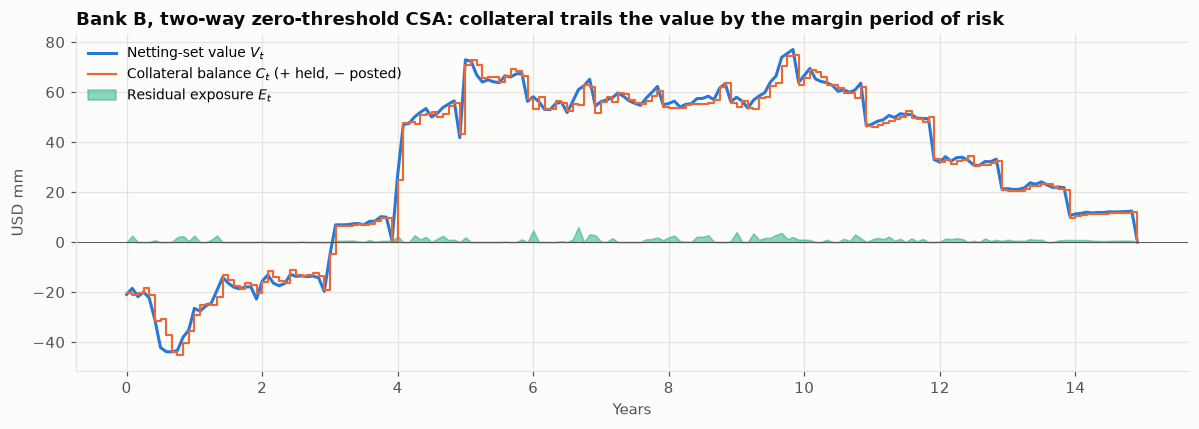

In [9]:
# --- Chart 1: CSA mechanics on one path
cp_demo = "Bank B"
r = reports[cp_demo]
# a lively but not extreme path
path = int(np.argsort(np.abs(r["v_now"]).max(axis=1))[int(0.9 * N_PATHS)])
coll_value, _ = apply_csa(
    r["v_now"],
    netted[cp_demo][:, I_LAG[10]],
    *CSA.loc[cp_demo, ["th_cp", "th_own", "mta", "ia"]],
)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(
    MONTHLY,
    r["v_now"][path],
    color=PALETTE[0],
    label="Netting-set value $V_t$",
)
ax.step(
    MONTHLY,
    r["collateral"][path],
    where="post",
    color=PALETTE[1],
    lw=1.4,
    label="Collateral balance $C_t$ (+ held, − posted)",
)
ax.fill_between(
    MONTHLY,
    0,
    np.maximum(coll_value[path], 0),
    color=PALETTE[2],
    alpha=0.5,
    label="Residual exposure $E_t$",
)
ax.axhline(0, color=INK_2, lw=0.6)
ax.set_title(
    f"{cp_demo}, two-way zero-threshold CSA: collateral trails the value by"
    " the margin period of risk"
)
ax.set_xlabel("Years")
ax.set_ylabel("USD mm")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
save_fig(fig, "01_csa_mechanics_one_path")
plt.show()

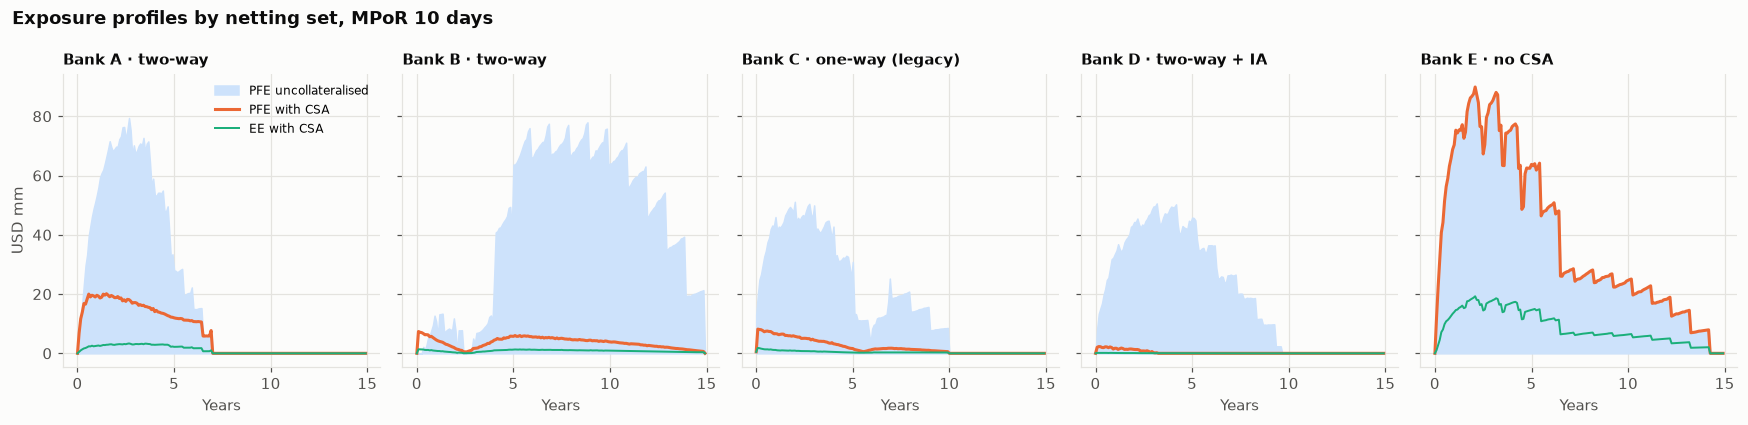

In [10]:
# --- Chart 2: exposure profiles with and without the CSA
fig, axes = plt.subplots(1, 5, figsize=(16, 3.9), sharey=True)
for ax, cp in zip(axes, COUNTERPARTIES):
    u, c = reports[cp]["uncoll"], reports[cp]["coll"]
    ax.fill_between(
        MONTHLY, 0, u["PFE"], color="#cde2fb", label="PFE uncollateralised"
    )
    ax.plot(MONTHLY, c["PFE"], color=PALETTE[1], label="PFE with CSA")
    ax.plot(MONTHLY, c["EE"], color=PALETTE[2], lw=1.3, label="EE with CSA")
    ax.set_title(f"{cp} · {CSA.loc[cp, 'csa']}", fontsize=10)
    ax.set_xlabel("Years")
axes[0].set_ylabel("USD mm")
axes[0].legend(fontsize=8)
fig.suptitle(
    "Exposure profiles by netting set, MPoR 10 days",
    x=0.01,
    ha="left",
    fontweight="bold",
    color=INK,
)
plt.tight_layout()
save_fig(fig, "02_profiles_with_and_without_csa")
plt.show()

## 7. What drives the residual exposure: MPoR and threshold

With a zero threshold, what is left is the move in value over the margin period of risk. Under diffusion that scales roughly with $\sqrt{\delta}$, so going from 10 to 20 days should raise collateralised PFE by about $\sqrt 2 \approx 1.41\times$. A threshold adds an unsecured layer on top.

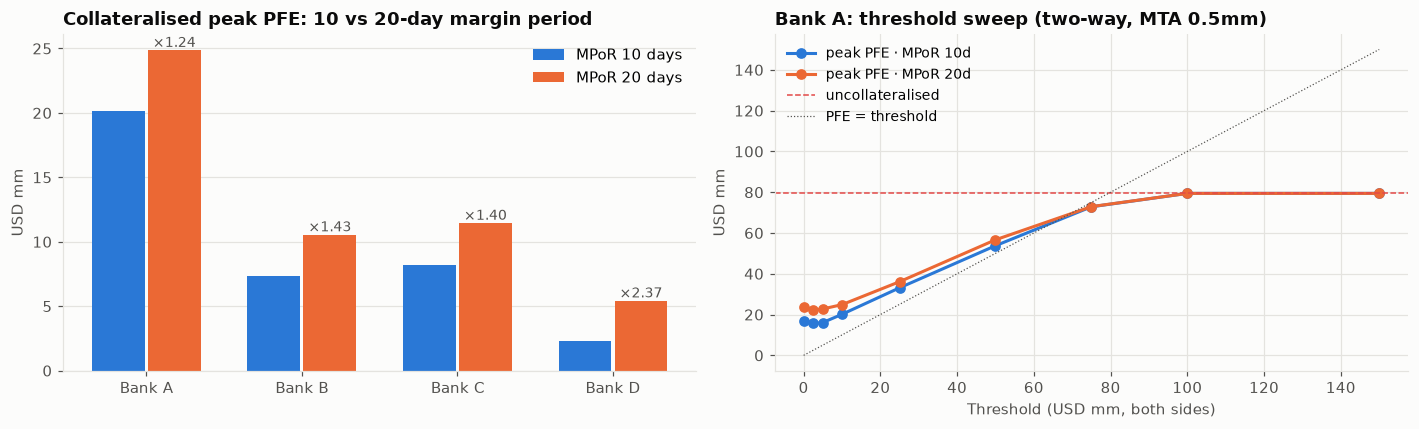

,peak PFE · MPoR 10d,peak PFE · MPoR 20d,ratio
counterparty,,,
Bank A,20.12,24.87,1.24
Bank B,7.36,10.56,1.43
Bank C,8.17,11.45,1.40
Bank D,2.29,5.43,2.37


In [11]:
mpor_rows = []
for cp in COUNTERPARTIES:
    if not np.isfinite(CSA.loc[cp, "th_cp"]):
        continue
    p10, p20 = (
        netting_set_report(cp, mpor=d)["coll"]["PFE"].max() for d in MPOR_DAYS
    )
    mpor_rows.append({
        "counterparty": cp,
        "peak PFE · MPoR 10d": p10,
        "peak PFE · MPoR 20d": p20,
        "ratio": p20 / p10,
    })
mpor_table = pd.DataFrame(mpor_rows).set_index("counterparty")

# Threshold sweep on the largest collateralised netting set (two-way, own
# threshold = bank threshold)
cp_sweep = csa_summary.loc[
    csa_summary["CSA"] != "no CSA", "peak PFE uncoll."
].idxmax()
thresholds = [0, 2.5, 5, 10, 25, 50, 75, 100, 150]
sweep = []
for th in thresholds:
    terms = {"th_cp": th, "th_own": th, "mta": 0.5, "ia": 0.0}
    for d in MPOR_DAYS:
        m = netting_set_report(cp_sweep, mpor=d, terms=terms)["coll"]
        sweep.append({
            "threshold": th,
            "mpor": d,
            "peak PFE": m["PFE"].max(),
            "EAD": ALPHA_IMM * m["EEPE"],
        })
sweep = pd.DataFrame(sweep)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
xp = np.arange(len(mpor_table))
ax.bar(
    xp - 0.18,
    mpor_table["peak PFE · MPoR 10d"],
    0.34,
    color=PALETTE[0],
    label="MPoR 10 days",
)
ax.bar(
    xp + 0.18,
    mpor_table["peak PFE · MPoR 20d"],
    0.34,
    color=PALETTE[1],
    label="MPoR 20 days",
)
for x_, rat, h in zip(
    xp, mpor_table["ratio"], mpor_table["peak PFE · MPoR 20d"]
):
    ax.text(
        x_ + 0.18,
        h,
        f"×{rat:.2f}",
        ha="center",
        va="bottom",
        fontsize=9,
        color=INK_2,
    )
ax.set_xticks(xp, mpor_table.index)
ax.set_title("Collateralised peak PFE: 10 vs 20-day margin period")
ax.set_ylabel("USD mm")
ax.legend()
ax.grid(axis="x", visible=False)
ax = axes[1]
for d, color in zip(MPOR_DAYS, PALETTE[:2]):
    s = sweep[sweep["mpor"] == d]
    ax.plot(
        s["threshold"],
        s["peak PFE"],
        "o-",
        color=color,
        label=f"peak PFE · MPoR {d}d",
    )
ax.axhline(
    csa_summary.loc[cp_sweep, "peak PFE uncoll."],
    color=STATUS["red"],
    ls="--",
    lw=1,
    label="uncollateralised",
)
ax.plot(
    thresholds,
    thresholds,
    color=INK_2,
    lw=0.8,
    ls=":",
    label="PFE = threshold",
)
ax.set_title(f"{cp_sweep}: threshold sweep (two-way, MTA 0.5mm)")
ax.set_xlabel("Threshold (USD mm, both sides)")
ax.set_ylabel("USD mm")
ax.legend(fontsize=9)
plt.tight_layout()
save_fig(fig, "03_mpor_and_threshold_sensitivity")
plt.show()
mpor_table.round(2)

## 8. The other side of a two-way CSA: collateral the MDB must post

Two-way CSAs reduce credit exposure, but every time rates move against the MDB on a netting set, cash or Treasuries leave its liquidity portfolio. A treasury needs both the **expected** posting and a **stressed** (97.5%) posting by horizon to size its liquidity buffer. These feed the LCR and NSFR liquidity metrics.

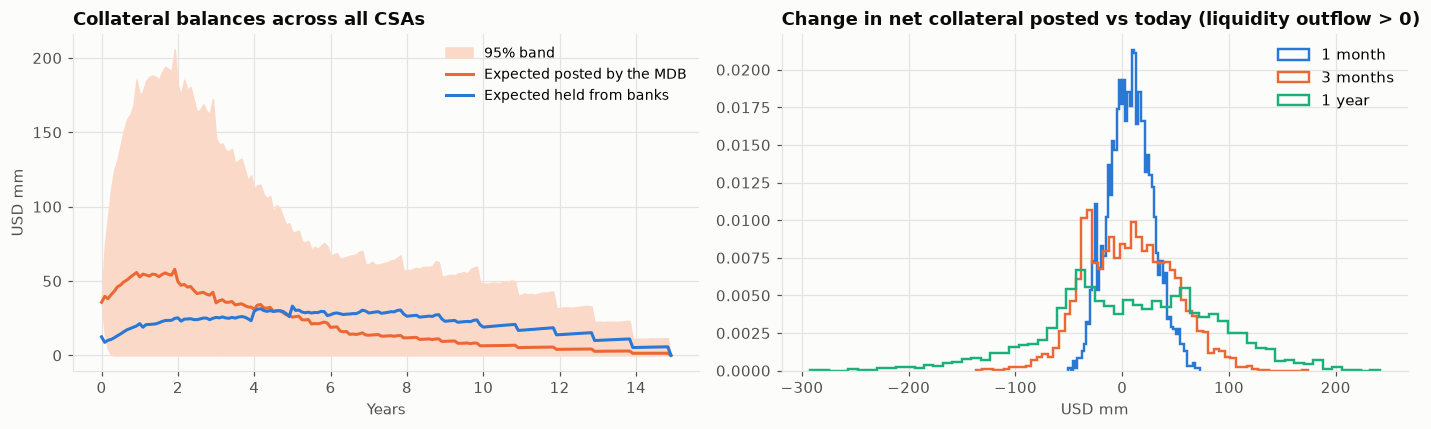

,expected net outflow,95% outflow,99% outflow
1 month,7.70,41.90,55.40
3 months,6.80,74.40,101.80
1 year,8.20,130.50,179.10


In [12]:
# paths × dates, all CSAs
posting = sum(
    np.maximum(-reports[cp]["collateral"], 0) for cp in COUNTERPARTIES
)
held = sum(np.maximum(reports[cp]["collateral"], 0) for cp in COUNTERPARTIES)
# >0: net posted
net_outflow_change = -(sum(reports[cp]["collateral"] for cp in COUNTERPARTIES))
# change vs today
net_outflow_change = net_outflow_change - net_outflow_change[:, [0]]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.fill_between(
    MONTHLY,
    np.quantile(posting, 0.025, axis=0),
    np.quantile(posting, 0.975, axis=0),
    color="#fbd9c9",
    label="95% band",
)
ax.plot(
    MONTHLY,
    posting.mean(axis=0),
    color=PALETTE[1],
    label="Expected posted by the MDB",
)
ax.plot(
    MONTHLY,
    held.mean(axis=0),
    color=PALETTE[0],
    label="Expected held from banks",
)
ax.set_title("Collateral balances across all CSAs")
ax.set_xlabel("Years")
ax.set_ylabel("USD mm")
ax.legend(fontsize=9)
ax = axes[1]
horizons = {"1 month": 1, "3 months": 3, "1 year": 12}
for (label, j), color in zip(horizons.items(), PALETTE):
    ax.hist(
        net_outflow_change[:, j],
        bins=60,
        histtype="step",
        lw=1.6,
        color=color,
        density=True,
        label=label,
    )
ax.set_title(
    "Change in net collateral posted vs today (liquidity outflow > 0)"
)
ax.set_xlabel("USD mm")
ax.legend()
plt.tight_layout()
save_fig(fig, "04_collateral_posted_liquidity")
plt.show()

liquidity = pd.DataFrame({
    h: {
        "expected net outflow": net_outflow_change[:, j].mean(),
        "95% outflow": np.quantile(net_outflow_change[:, j], 0.95),
        "99% outflow": np.quantile(net_outflow_change[:, j], 0.99),
    }
    for h, j in horizons.items()
}).T
liquidity.round(1)

## 9. A CSA negotiation surrogate: XGBoost + SHAP

When a bank asks for a higher threshold or the MDB considers moving a legacy relationship to a CSA, the credit officer wants an instant answer to the question *"how much exposure is left under these terms?"* The Monte Carlo engine can answer it, but a trained surrogate answers thousands of what-ifs in milliseconds, and SHAP shows **which terms matter most**.

**Training set.** 2,500 random designs, each one a netting set of 2–8 swaps (random tenor 2–15 years, direction, size and off-market rate) under random CSA terms (threshold 0–100mm, MTA, IA, MPoR, one-way or two-way). Each design is valued on 1,500 paths. Swaps are linear in notional and fixed rate, so the annuity and floating leg of each template tenor are simulated once and every design is a weighted sum: exact values with no re-simulation.

**Target.** Residual peak PFE as a % of the uncollateralised peak PFE, which is the share of the exposure the CSA *fails* to remove. Thresholds, MTA and IA enter both in USD and relative to the uncollateralised PFE.

In [13]:
sim_ml = {
    k: v[:N_PATHS_ML] if isinstance(v, np.ndarray) else v
    for k, v in sim.items()
}
# (first payment, n payments)
TEMPLATES = [(fp, n) for n in (2, 3, 5, 7, 10, 12, 15) for fp in (1.0, 0.5)]
t0 = time.perf_counter()
legs = [swap_legs(fp, n, hw, sim_ml, cutoff=CUTOFF) for fp, n in TEMPLATES]
par = np.array([par_rate(CURVE, fp, n) for fp, n in TEMPLATES])
# annuity today (path-independent)
ann0 = np.array([a[0, 0] for a, _ in legs])
print(
    f"{len(TEMPLATES)} template swaps simulated in"
    f" {time.perf_counter() - t0:.1f}s"
)

design_rng = np.random.default_rng(SEED + 7)
records = []
t0 = time.perf_counter()
for _ in range(N_DESIGNS):
    k = int(design_rng.integers(2, 9))
    idx = design_rng.integers(0, len(TEMPLATES), k)
    omega = design_rng.choice([-1.0, 1.0], k)
    notional = design_rng.choice([25.0, 50, 100, 200, 300, 500], k)
    offset = design_rng.normal(0, 0.0075, k) * (design_rng.random(k) < 0.6)
    v = sum(
        w * ((par[i] + o) * legs[i][0] - legs[i][1]) * n
        for i, w, n, o in zip(idx, omega, notional, offset)
    )
    two_way = design_rng.random() < 0.7
    th = float(design_rng.choice([0, 0, 2, 5, 10, 25, 50, 100]))
    mta = float(design_rng.choice([0.1, 0.25, 0.5, 1.0, 2.0]))
    ia = float(design_rng.choice([0, 0, 0, 2, 5, 10]))
    mpor = int(design_rng.choice(MPOR_DAYS))
    v_now, v_lag = v[:, I_NOW], v[:, I_LAG[mpor]]
    pfe_u = np.quantile(np.maximum(v_now, 0), PFE_QUANTILE, axis=0).max()
    if pfe_u < 1.0:
        # nothing to collateralise
        continue
    cv, _ = apply_csa(v_now, v_lag, th, th if two_way else INF, mta, ia)
    pfe_c = np.quantile(np.maximum(cv, 0), PFE_QUANTILE, axis=0).max()
    # USD mm per bp, receiver positive
    dv01 = omega * notional * ann0[idx] * 1e-4
    mats = np.array([TEMPLATES[i][0] + TEMPLATES[i][1] - 1 for i in idx])
    records.append({
        "threshold": th,
        "threshold_rel": th / pfe_u,
        "mta_rel": mta / pfe_u,
        "ia_rel": ia / pfe_u,
        "mpor_days": mpor,
        "two_way": int(two_way),
        "n_trades": k,
        "mtm_today_rel": v_now[:, 0].mean() / pfe_u,
        "dv01_balance": abs(dv01.sum()) / np.abs(dv01).sum(),
        "wavg_maturity": np.average(mats, weights=notional),
        "uncoll_pfe": pfe_u,
        "residual_pct": pfe_c / pfe_u * 100,
    })
designs = pd.DataFrame(records)
print(
    f"{len(designs):,} designs valued in {time.perf_counter() - t0:.0f}s ·"
    f" residual PFE median {designs['residual_pct'].median():.0f}% of"
    " uncollateralised"
)
designs.describe().T[["mean", "min", "50%", "max"]].round(2)

14 template swaps simulated in 0.6s


2,495 designs valued in 62s · residual PFE median 22% of uncollateralised


,mean,min,50%,max
threshold,23.45,0.00,5.00,100.00
threshold_rel,0.66,0.00,0.11,44.79
mta_rel,0.02,0.00,0.01,1.39
ia_rel,0.08,0.00,0.01,4.48
mpor_days,15.28,10.00,20.00,20.00
two_way,0.70,0.00,1.00,1.00
n_trades,5.03,2.00,5.00,8.00
mtm_today_rel,-0.10,-28.41,-0.00,0.96
dv01_balance,0.54,0.00,0.53,1.00
wavg_maturity,7.52,1.58,7.43,15.00


XGBoost surrogate on held-out designs: R² 0.989 · MAE 2.23 pp


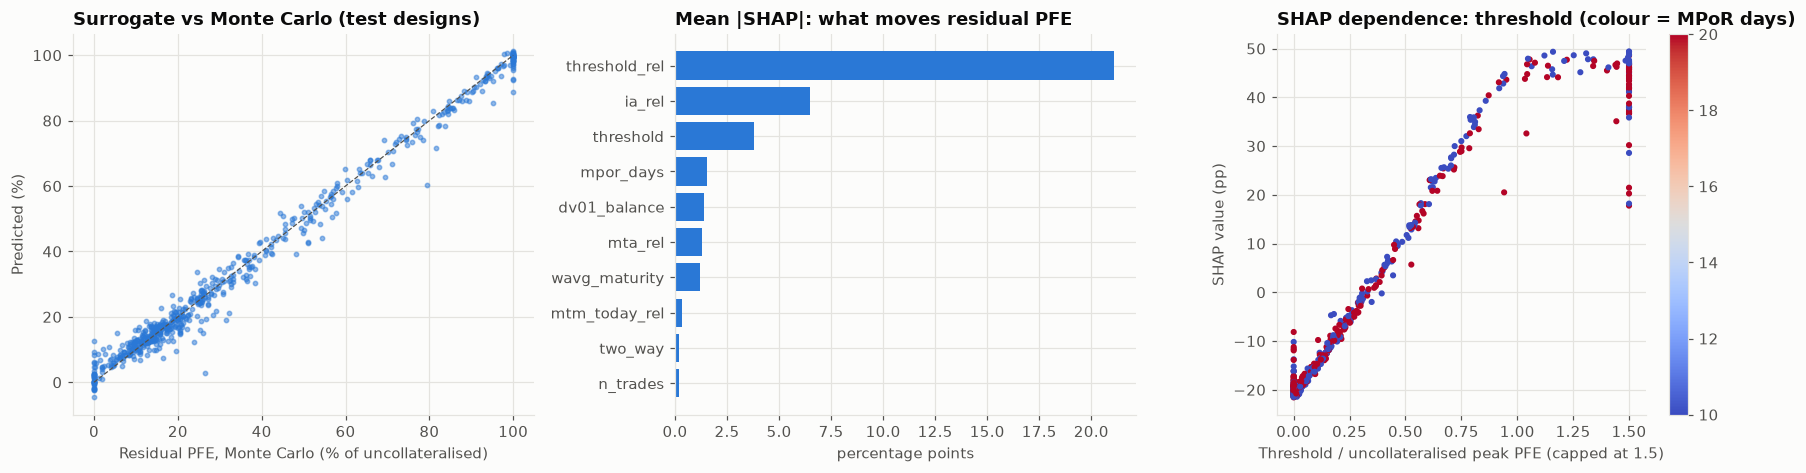

threshold_rel   21.10
ia_rel           6.47
threshold        3.78
mpor_days        1.52
dv01_balance     1.40
mta_rel          1.31
wavg_maturity    1.20
mtm_today_rel    0.35
two_way          0.19
n_trades         0.17
dtype: float32

In [14]:
FEATURES = [
    "threshold_rel",
    "threshold",
    "mta_rel",
    "ia_rel",
    "mpor_days",
    "two_way",
    "n_trades",
    "mtm_today_rel",
    "dv01_balance",
    "wavg_maturity",
]
X_tr, X_te, y_tr, y_te = train_test_split(
    designs[FEATURES],
    designs["residual_pct"],
    test_size=0.25,
    random_state=SEED,
)
model = xgb.XGBRegressor(
    n_estimators=600,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    random_state=SEED,
    n_jobs=2,
)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print(
    f"XGBoost surrogate on held-out designs: R² {r2_score(y_te, pred):.3f} ·"
    f" MAE {mean_absolute_error(y_te, pred):.2f} pp"
)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_te)
importance = pd.Series(
    np.abs(shap_values).mean(axis=0), index=FEATURES
).sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
ax = axes[0]
ax.scatter(y_te, pred, s=8, color=PALETTE[0], alpha=0.5)
ax.plot([0, y_te.max()], [0, y_te.max()], color=INK_2, ls="--", lw=0.8)
ax.set_title("Surrogate vs Monte Carlo (test designs)")
ax.set_xlabel("Residual PFE, Monte Carlo (% of uncollateralised)")
ax.set_ylabel("Predicted (%)")
ax = axes[1]
ax.barh(importance.index[::-1], importance.values[::-1], color=PALETTE[0])
ax.set_title("Mean |SHAP|: what moves residual PFE")
ax.set_xlabel("percentage points")
ax = axes[2]
j_th, j_mp = FEATURES.index("threshold_rel"), FEATURES.index("mpor_days")
sc = ax.scatter(
    X_te["threshold_rel"].clip(upper=1.5),
    shap_values[:, j_th],
    c=X_te["mpor_days"],
    cmap="coolwarm",
    s=9,
)
ax.set_title("SHAP dependence: threshold (colour = MPoR days)")
ax.set_xlabel("Threshold / uncollateralised peak PFE (capped at 1.5)")
ax.set_ylabel("SHAP value (pp)")
plt.colorbar(sc, ax=ax)
plt.tight_layout()
save_fig(fig, "05_xgboost_shap_csa_terms")
plt.show()
importance.round(2)

### Using the surrogate: proposing a CSA to the uncollateralised bank

Bank E has no CSA. Below are five options a negotiator might table. For each one the surrogate gives the residual PFE instantly, and the full Monte Carlo confirms it.

In [15]:
cp_new = "Bank E"
v = netted[cp_new]
pfe_u = reports[cp_new]["uncoll"]["PFE"].max()
mats = book.loc[book["counterparty"] == cp_new]
dv01 = (
    mats["omega"]
    * mats["notional_mm"]
    * [
        swap_legs(fp, n, hw, sim_ml)[0][0, 0]
        for fp, n in zip(mats["first_pay"], mats["n_pay"])
    ]
).to_numpy() * 1e-4
OPTIONS = {
    "Two-way, TH 0, MPoR 10d": (0, True, 0.5, 0, 10),
    "Two-way, TH 10": (10, True, 0.5, 0, 10),
    "Two-way, TH 25": (25, True, 0.5, 0, 10),
    "One-way (bank posts), TH 0": (0, False, 0.5, 0, 10),
    "Two-way, TH 0, MPoR 20d (disputes)": (0, True, 0.5, 0, 20),
    "Two-way, TH 0 + IA 5mm": (0, True, 0.5, 5, 10),
}
rows = []
for name, (th, two_way, mta, ia, mpor) in OPTIONS.items():
    feats = {
        "threshold_rel": th / pfe_u,
        "threshold": th,
        "mta_rel": mta / pfe_u,
        "ia_rel": ia / pfe_u,
        "mpor_days": mpor,
        "two_way": int(two_way),
        "n_trades": len(mats),
        "mtm_today_rel": v[:, 0].mean() / pfe_u,
        "dv01_balance": abs(dv01.sum()) / np.abs(dv01).sum(),
        "wavg_maturity": np.average(
            mats["maturity_y"], weights=mats["notional_mm"]
        ),
    }
    cv, coll = apply_csa(
        v[:, I_NOW], v[:, I_LAG[mpor]], th, th if two_way else INF, mta, ia
    )
    exact = np.quantile(np.maximum(cv, 0), PFE_QUANTILE, axis=0).max()
    rows.append({
        "option": name,
        "predicted residual PFE": (
            model.predict(pd.DataFrame([feats])[FEATURES])[0] / 100 * pfe_u
        ),
        "Monte Carlo residual PFE": exact,
        "MDB max 97.5% posting": np.quantile(
            np.maximum(-coll, 0), 0.975, axis=0
        ).max(),
    })
negotiation = pd.DataFrame(rows).set_index("option")
negotiation.insert(0, "uncollateralised PFE", pfe_u)
csa_summary.to_csv(OUT_DIR / "csa_exposure_summary.csv")
negotiation.to_csv(OUT_DIR / "csa_negotiation_options.csv")
designs.to_csv(OUT_DIR / "csa_design_training_set.csv", index=False)
negotiation.round(1)

,uncollateralised PFE,predicted residual PFE,Monte Carlo residual PFE,MDB max 97.5% posting
option,,,,
"Two-way, TH 0, MPoR 10d",89.90,14.70,16.60,100.40
"Two-way, TH 10",89.90,21.80,21.70,90.40
"Two-way, TH 25",89.90,32.70,34.60,75.40
"One-way (bank posts), TH 0",89.90,12.60,13.30,0.00
"Two-way, TH 0, MPoR 20d (disputes)",89.90,20.30,23.60,98.30
"Two-way, TH 0 + IA 5mm",89.90,9.20,11.60,100.40


## 10. Reading the results and limitations

These figures come from the run of 16 October 2026.

**A zero-threshold two-way CSA removes about 90% of peak PFE.** Bank B drops from 78 to 7mm, and Bank D, which also posts a 5mm independent amount, drops 95%. What is left is the change in value over the margin period of risk.

**MPoR matters as diffusion predicts.** For zero-threshold CSAs, moving from 10 to 20 days raises residual PFE by ×1.40–1.43, close to $\sqrt2$. That is why the 20-day Basel floor for large or disputed netting sets is costly.

Bank A's ratio is lower (×1.24) because its 10mm threshold is a fixed layer. Bank D's is higher (×2.4) because the independent amount absorbs most 10-day moves but not 20-day ones.

**Thresholds are unsecured credit lines.** In the sweep, PFE climbs almost one for one with the threshold until it meets the uncollateralised profile. A threshold should be approved like an unsecured line.

**Two-way CSAs cut both ways.** Bank B's *EEPE* goes **up** with the CSA (0.3 → 1.3mm). Its book is 21mm out of the money for the MDB, so the MDB has posted that collateral and would have to claim it back if the bank defaulted.

Across all CSAs, the net collateral the MDB may have to post grows by up to about 100mm at a 99% level over three months, and up to 180mm over a year. That outflow belongs in the liquidity buffer.

The legacy one-way CSA (Bank C) gives most of the credit benefit with none of the liquidity cost.

**The surrogate is accurate and explains the trade-offs.** XGBoost reproduces Monte Carlo residual PFE with R² 0.99 (MAE about 2 pp).

SHAP ranks the threshold relative to the exposure far above everything else, followed by the independent amount and the MPoR. MTA, DV01 balance and maturity are second-order.

For Bank E's negotiation, a two-way zero-threshold CSA leaves about 17mm of its 90mm PFE, a one-way CSA about 13mm, and conceding a 25mm threshold about 35mm.

**Limitations**

- Classical+ collateral model: trade flows are paid during the MPoR, there is no daily margining path, and MTA is treated as an extra threshold (a conservative choice).
- Collateral is assumed to be cash with no haircut. Securities collateral adds haircut and wrong-way questions.
- One-factor rates model. Initial margin under the uncleared margin rules (SIMM) is outside scope.
- The surrogate is only valid inside the range of designs it was trained on.

## References

### Finance and regulation

- Andersen, L., Pykhtin, M., & Sokol, A. (2017). Rethinking the margin period of risk. *Journal of Credit Risk, 13*(1), 1–45. https://doi.org/10.21314/JCR.2016.218
- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Basel Committee on Banking Supervision. (2014). *The standardised approach for measuring counterparty credit risk exposures*. Bank for International Settlements. https://www.bis.org/publ/bcbs279.htm
- Basel Committee on Banking Supervision & International Organization of Securities Commissions. (2020). *Margin requirements for non-centrally cleared derivatives*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d499.htm
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573
- Brigo, D., Morini, M., & Pallavicini, A. (2013). *Counterparty credit risk, collateral and funding: With pricing cases for all asset classes*. Wiley. https://doi.org/10.1002/9781118818589

### Machine learning and deep learning

- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining*. https://doi.org/10.1145/2939672.2939785
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems, 30*. https://arxiv.org/abs/1705.07874
- Lundberg, S. M., Erion, G., Chen, H., DeGrave, A., Prutkin, J. M., Nair, B., … Lee, S.-I. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence, 2*(1), 56–67. https://doi.org/10.1038/s42256-019-0138-9